# Resultados por Run — Investigathon 2026
Datos extraídos de los archivos de análisis y logs de cada run.
Baseline = búsqueda aleatoria 10k muestras. SA = Simulated Annealing.

In [1]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

plt.rcParams.update({
    'figure.dpi': 120,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.3,
})

RUNS = [1, 2, 3, 4, 5, 6]
RUN_LABELS = ['Run 1\nREINFORCE\n200ep', 'Run 2\nA2C\n500ep', 'Run 3\nA2C+fixes\n1000ep',
              'Run 4\nA2C+sparse\n2000ep', 'Run 5\nA2C+GAE\n200ep', 'Run 6\nA2C+GAE+fix\n1000ep']

# Métricas por run (score/paso)
mejor_score  = [-0.320, -0.110, -0.092, -0.163, -0.236, -0.155]
score_media  = [-0.580, -0.397, -0.369, -0.424, -0.435, -0.444]
conn_max     = [0.200,  0.300,  0.444,  0.689,  0.578,  0.578]
conn_media   = [0.100,  0.150,  0.280,  0.430,  0.347,  0.361]
r_media      = [0.998,  0.782,  0.841,  0.956,  0.900,  0.920]
tendencia    = [-0.0060, +0.0010, +0.0002, +0.000002, 0.0, 0.0]  # por episodio

# Referencias
BASELINE = +0.093   # búsqueda aleatoria 10k muestras
SA_SCORE = +0.168   # Simulated Annealing

# Paleta
COLOR_RUNS = plt.cm.viridis(np.linspace(0.15, 0.85, len(RUNS)))
COLOR_BASE = '#e05c2e'
COLOR_SA   = '#2eaae0'

print('Datos cargados.')

Datos cargados.


## 1. Mejor score por run

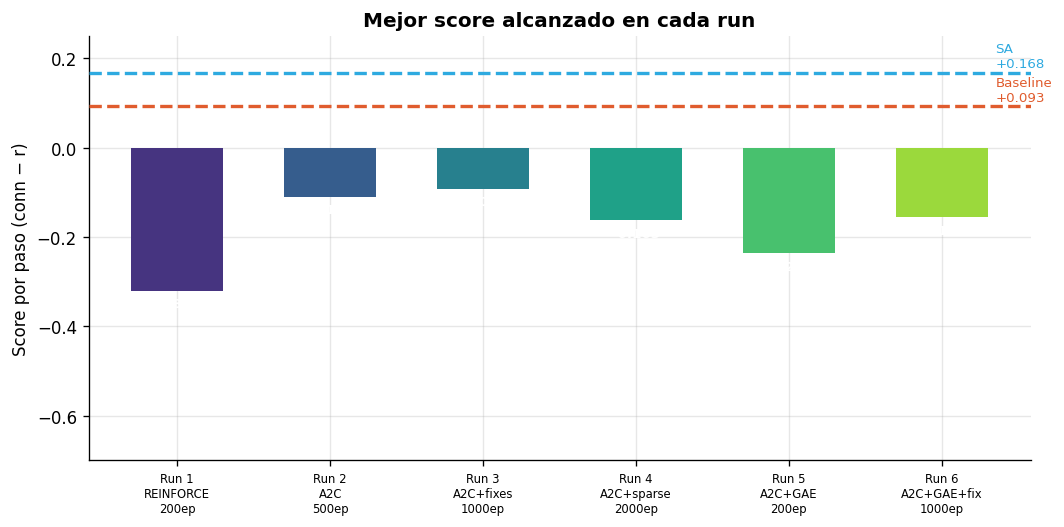

In [2]:
fig, ax = plt.subplots(figsize=(9, 4.5))

bars = ax.bar(RUNS, mejor_score, color=COLOR_RUNS, width=0.6, zorder=3)

ax.axhline(BASELINE, color=COLOR_BASE, lw=2, ls='--', zorder=4)
ax.axhline(SA_SCORE,  color=COLOR_SA,   lw=2, ls='--', zorder=4)
ax.text(6.35, BASELINE + 0.005, f'Baseline\n+{BASELINE:.3f}', color=COLOR_BASE, va='bottom', fontsize=8)
ax.text(6.35, SA_SCORE  + 0.005, f'SA\n+{SA_SCORE:.3f}',      color=COLOR_SA,   va='bottom', fontsize=8)

for bar, val in zip(bars, mejor_score):
    ax.text(bar.get_x() + bar.get_width()/2, val - 0.015,
            f'{val:.3f}', ha='center', va='top', fontsize=8, color='white', fontweight='bold')

ax.set_xticks(RUNS)
ax.set_xticklabels(RUN_LABELS, fontsize=7)
ax.set_ylabel('Score por paso (conn − r)')
ax.set_title('Mejor score alcanzado en cada run', fontweight='bold')
ax.set_ylim(-0.70, 0.25)
fig.tight_layout()
plt.show()

## 2. Score medio por run

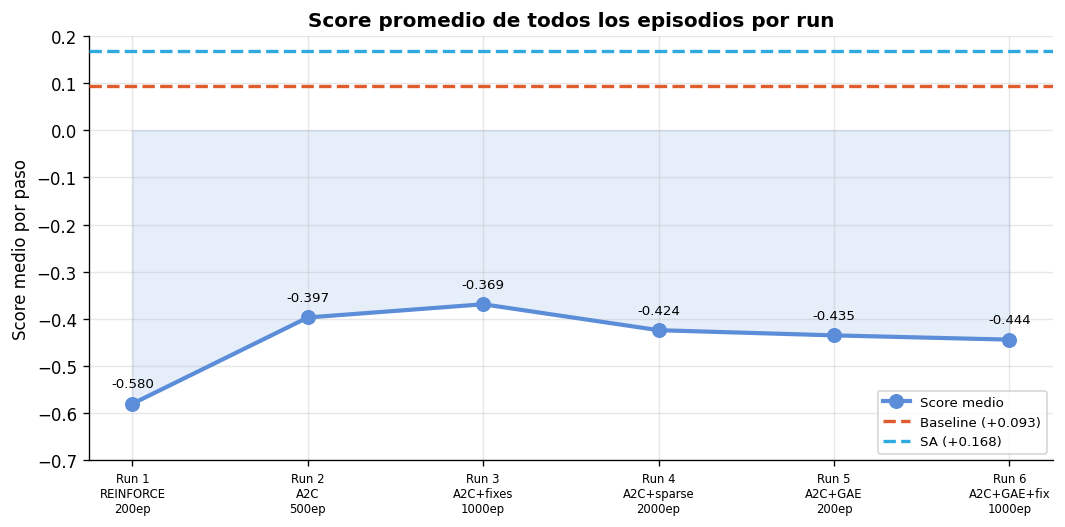

In [3]:
fig, ax = plt.subplots(figsize=(9, 4.5))

ax.plot(RUNS, score_media, 'o-', color='#5b8dd9', lw=2.5, ms=8, zorder=3, label='Score medio')
ax.fill_between(RUNS, score_media, alpha=0.15, color='#5b8dd9')

ax.axhline(BASELINE, color=COLOR_BASE, lw=2, ls='--', zorder=4, label=f'Baseline ({BASELINE:+.3f})')
ax.axhline(SA_SCORE,  color=COLOR_SA,   lw=2, ls='--', zorder=4, label=f'SA ({SA_SCORE:+.3f})')

for x, y in zip(RUNS, score_media):
    ax.annotate(f'{y:.3f}', (x, y), textcoords='offset points', xytext=(0, 10),
                ha='center', fontsize=8)

ax.set_xticks(RUNS)
ax.set_xticklabels(RUN_LABELS, fontsize=7)
ax.set_ylabel('Score medio por paso')
ax.set_title('Score promedio de todos los episodios por run', fontweight='bold')
ax.set_ylim(-0.70, 0.20)
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

## 3. Conectividad máxima y media por run

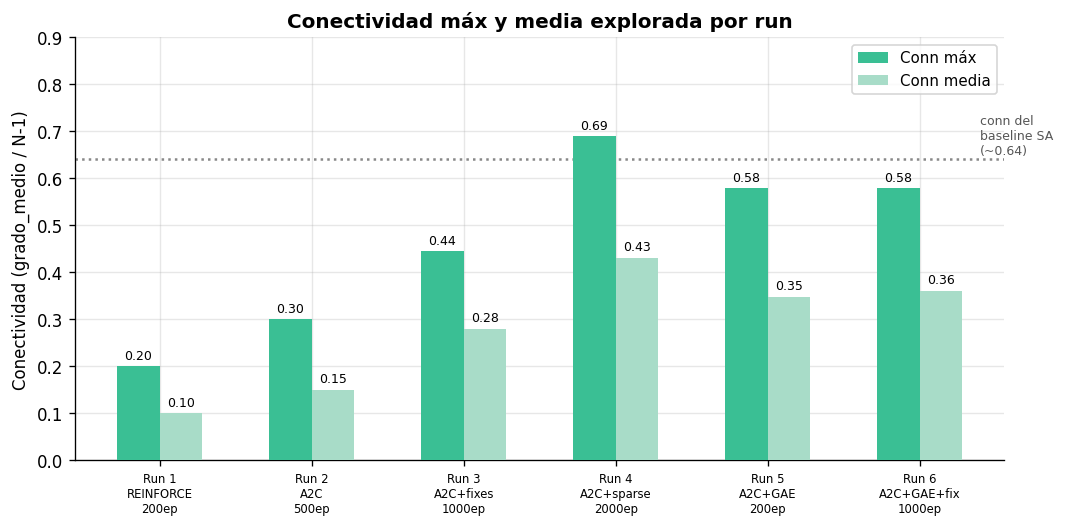

In [4]:
fig, ax = plt.subplots(figsize=(9, 4.5))

x = np.array(RUNS)
w = 0.28

b1 = ax.bar(x - w/2, conn_max,   width=w, label='Conn máx',   color='#3abf94', zorder=3)
b2 = ax.bar(x + w/2, conn_media, width=w, label='Conn media', color='#a8dcc8', zorder=3)

ax.axhline(0.64, color='#888', lw=1.5, ls=':', zorder=2)
ax.text(6.4, 0.645, 'conn del\nbaseline SA\n(~0.64)', fontsize=7.5, color='#555', va='bottom')

for bar, val in zip(list(b1) + list(b2), conn_max + conn_media):
    ax.text(bar.get_x() + bar.get_width()/2, val + 0.01,
            f'{val:.2f}', ha='center', va='bottom', fontsize=7.5)

ax.set_xticks(RUNS)
ax.set_xticklabels(RUN_LABELS, fontsize=7)
ax.set_ylabel('Conectividad (grado_medio / N-1)')
ax.set_title('Conectividad máx y media explorada por run', fontweight='bold')
ax.set_ylim(0, 0.90)
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

## 4. Parámetro r medio por run (sincronización)

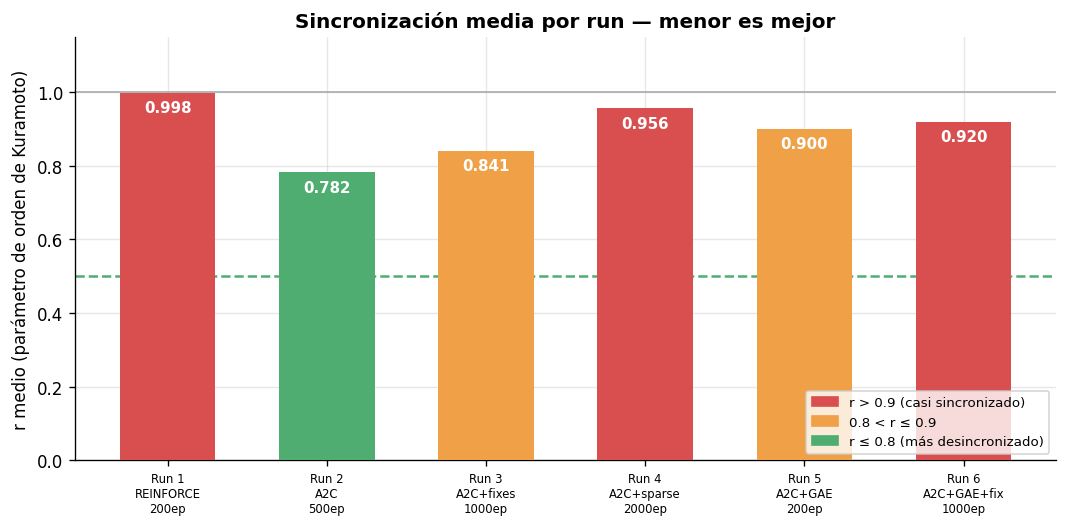

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.5))

colors = ['#d94f4f' if r > 0.9 else '#f0a047' if r > 0.8 else '#4fad72' for r in r_media]
bars = ax.bar(RUNS, r_media, color=colors, width=0.6, zorder=3)

ax.axhline(1.0, color='#aaa', lw=1, ls='-')
ax.axhline(0.5, color='#4fad72', lw=1.5, ls='--', label='r=0.5 (umbral desincronización parcial)')

for bar, val in zip(bars, r_media):
    ax.text(bar.get_x() + bar.get_width()/2, val - 0.02,
            f'{val:.3f}', ha='center', va='top', fontsize=9, color='white', fontweight='bold')

red_p   = mpatches.Patch(color='#d94f4f', label='r > 0.9 (casi sincronizado)')
orange_p = mpatches.Patch(color='#f0a047', label='0.8 < r ≤ 0.9')
green_p  = mpatches.Patch(color='#4fad72', label='r ≤ 0.8 (más desincronizado)')

ax.set_xticks(RUNS)
ax.set_xticklabels(RUN_LABELS, fontsize=7)
ax.set_ylabel('r medio (parámetro de orden de Kuramoto)')
ax.set_title('Sincronización media por run — menor es mejor', fontweight='bold')
ax.set_ylim(0, 1.15)
ax.legend(handles=[red_p, orange_p, green_p], fontsize=8, loc='lower right')
fig.tight_layout()
plt.show()

## 5. Tendencia de aprendizaje (slope del score por episodio)

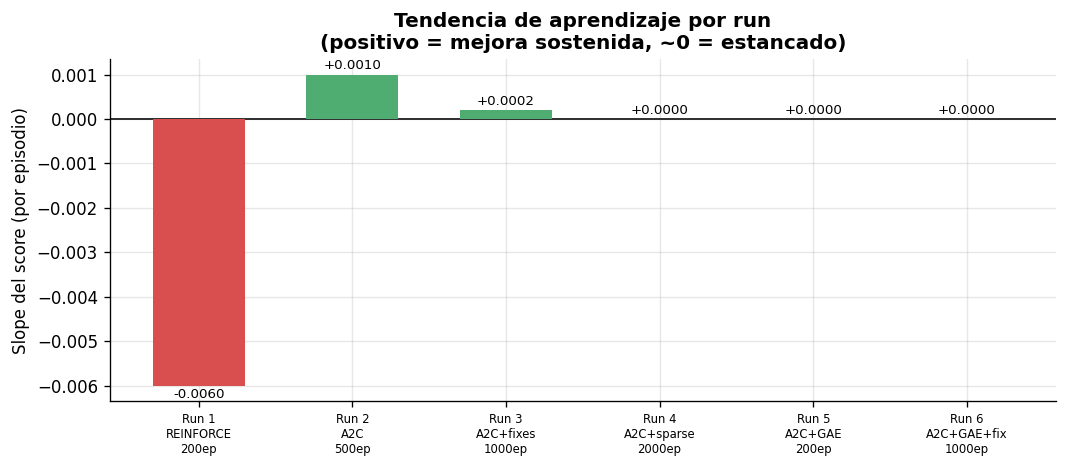

In [6]:
fig, ax = plt.subplots(figsize=(9, 4))

colors_t = ['#4fad72' if t > 0 else '#d94f4f' for t in tendencia]
bars = ax.bar(RUNS, tendencia, color=colors_t, width=0.6, zorder=3)
ax.axhline(0, color='#333', lw=1.2)

for bar, val in zip(bars, tendencia):
    offset = 0.00005 if val >= 0 else -0.00005
    va = 'bottom' if val >= 0 else 'top'
    ax.text(bar.get_x() + bar.get_width()/2, val + offset,
            f'{val:+.4f}', ha='center', va=va, fontsize=8)

ax.set_xticks(RUNS)
ax.set_xticklabels(RUN_LABELS, fontsize=7)
ax.set_ylabel('Slope del score (por episodio)')
ax.set_title('Tendencia de aprendizaje por run\n(positivo = mejora sostenida, ~0 = estancado)', fontweight='bold')
fig.tight_layout()
plt.show()

## 6. r vs Conectividad — mejores episodios de cada run
Muestra la tensión entre conectividad y sincronización. El objetivo es llegar a la esquina inferior derecha (alta conn, bajo r).

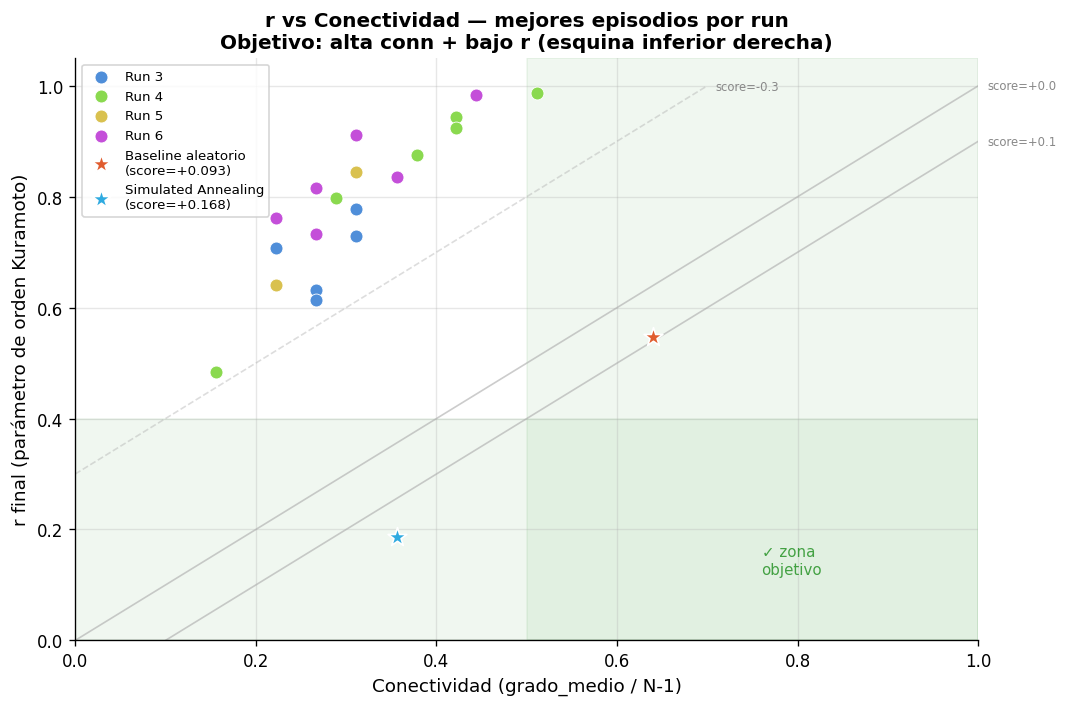

In [7]:
# Datos: mejores episodios ('nuevo mejor') de cada run
# Formato: (conn, r, score, run_id)
mejores_eps = [
    # Run 3
    (0.311, 0.777, -0.466, 3), (0.222, 0.707, -0.485, 3),
    (0.267, 0.631, -0.364, 3), (0.311, 0.729, -0.418, 3),
    (0.267, 0.614, -0.347, 3),  # ← mejor R3
    # Run 4
    (0.289, 0.798, -0.367, 4), (0.422, 0.944, -0.318, 4),
    (0.156, 0.483, -0.281, 4), (0.511, 0.986, -0.272, 4),
    (0.422, 0.923, -0.211, 4), (0.378, 0.875, -0.163, 4),  # ← mejor R4
    # Run 5
    (0.311, 0.844, -0.269, 5), (0.222, 0.641, -0.236, 5),  # ← mejor R5
    # Run 6
    (0.444, 0.983, -0.476, 6), (0.311, 0.911, -0.374, 6),
    (0.222, 0.761, -0.338, 6), (0.267, 0.816, -0.292, 6),
    (0.267, 0.732, -0.178, 6), (0.356, 0.836, -0.155, 6),  # ← mejor R6
]

# Baseline y SA como puntos de referencia (estimados)
# Baseline aleatorio: conn≈0.64, score=+0.093 → r = conn - score = 0.64 - 0.093 = 0.547
# SA: conn=0.356, r=0.187, score=+0.168

conn_ep = [x[0] for x in mejores_eps]
r_ep    = [x[1] for x in mejores_eps]
sc_ep   = [x[2] for x in mejores_eps]
run_ep  = [x[3] for x in mejores_eps]

run_colors = {3: '#4f8ed9', 4: '#8ad94f', 5: '#d9c14f', 6: '#c44fd9'}

fig, ax = plt.subplots(figsize=(9, 6))

# Región objetivo
ax.axvspan(0.5, 1.0, alpha=0.06, color='green')
ax.axhspan(0.0, 0.4, alpha=0.06, color='green')
ax.text(0.76, 0.12, '✓ zona\nobjetivo', color='green', fontsize=9, alpha=0.7)

for run_id in [3, 4, 5, 6]:
    xs = [x[0] for x in mejores_eps if x[3] == run_id]
    ys = [x[1] for x in mejores_eps if x[3] == run_id]
    ax.scatter(xs, ys, color=run_colors[run_id], s=60, zorder=4,
               label=f'Run {run_id}', edgecolors='white', lw=0.5)

# Baseline y SA
ax.scatter([0.64], [0.547], color=COLOR_BASE, s=140, marker='*', zorder=5,
           label=f'Baseline aleatorio\n(score=+0.093)', edgecolors='white')
ax.scatter([0.356], [0.187], color=COLOR_SA, s=140, marker='*', zorder=5,
           label=f'Simulated Annealing\n(score=+0.168)', edgecolors='white')

# Líneas iso-score (conn - r = cte)
c_vals = np.linspace(0, 1, 200)
for iso, ls, alpha in [(-0.3, '--', 0.4), (0.0, '-', 0.6), (+0.1, '-', 0.6)]:
    r_iso = c_vals - iso
    mask  = (r_iso >= 0) & (r_iso <= 1)
    ax.plot(c_vals[mask], r_iso[mask], ls=ls, lw=1, color='#aaa', alpha=alpha)
    ax.text(c_vals[mask][-1] + 0.01, r_iso[mask][-1],
            f'score={iso:+.1f}', fontsize=7, color='#888', va='center')

ax.set_xlabel('Conectividad (grado_medio / N-1)', fontsize=11)
ax.set_ylabel('r final (parámetro de orden Kuramoto)', fontsize=11)
ax.set_title('r vs Conectividad — mejores episodios por run\n'
             'Objetivo: alta conn + bajo r (esquina inferior derecha)', fontweight='bold')
ax.set_xlim(0, 1.0)
ax.set_ylim(0, 1.05)
ax.legend(fontsize=8, loc='upper left')
fig.tight_layout()
plt.show()

## 7. Resumen comparativo — tabla numérica

In [8]:
import pandas as pd

df = pd.DataFrame({
    'Run':          ['Run 1', 'Run 2', 'Run 3', 'Run 4', 'Run 5', 'Run 6', 'Baseline', 'SA'],
    'Algoritmo':    ['REINFORCE','A2C','A2C+fixes','A2C+sparse','A2C+GAE','A2C+GAE+fix','Aleatorio','Sim.Anneal.'],
    'Episodios':    [200, 500, 1000, 2000, 200, 1000, '10k muestras', '—'],
    'Mejor score':  [-0.320, -0.110, -0.092, -0.163, -0.236, -0.155, +0.093, +0.168],
    'Score medio':  [-0.580, -0.397, -0.369, -0.424, -0.435, -0.444, -0.392, '—'],
    'Conn máx':     [0.20,  0.30,  0.44,  0.69,  0.578, 0.578, 0.64, 0.356],
    'Conn media':   [0.10,  0.15,  0.28,  0.43,  0.347, 0.361, '—', '—'],
    'r medio':      [0.998, 0.782, 0.841, 0.956, 0.900, 0.920, '—', 0.187],
})

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 120)
df

,Run,Algoritmo,Episodios,Mejor score,Score medio,Conn máx,Conn media,r medio
0,Run 1,REINFORCE,200,-0.320,-0.58,0.200,0.1,0.998
1,Run 2,A2C,500,-0.110,-0.397,0.300,0.15,0.782
2,Run 3,A2C+fixes,1000,-0.092,-0.369,0.440,0.28,0.841
3,Run 4,A2C+sparse,2000,-0.163,-0.424,0.690,0.43,0.956
4,Run 5,A2C+GAE,200,-0.236,-0.435,0.578,0.347,0.9
5,Run 6,A2C+GAE+fix,1000,-0.155,-0.444,0.578,0.361,0.92
6,Baseline,Aleatorio,10k muestras,0.093,-0.392,0.640,—,—
7,SA,Sim.Anneal.,—,0.168,—,0.356,—,0.187


## 8. Grafo conocido para intentar acercarnos a la cota inferior.

<>:50: SyntaxWarning: invalid escape sequence '\e'
<>:50: SyntaxWarning: invalid escape sequence '\e'
C:\Users\AGUSTINA\AppData\Local\Temp\ipykernel_29932\781631691.py:50: SyntaxWarning: invalid escape sequence '\e'
  f"Grafo Circulante de Kuramoto ($n = {n}, \ell = {l}$)\n"


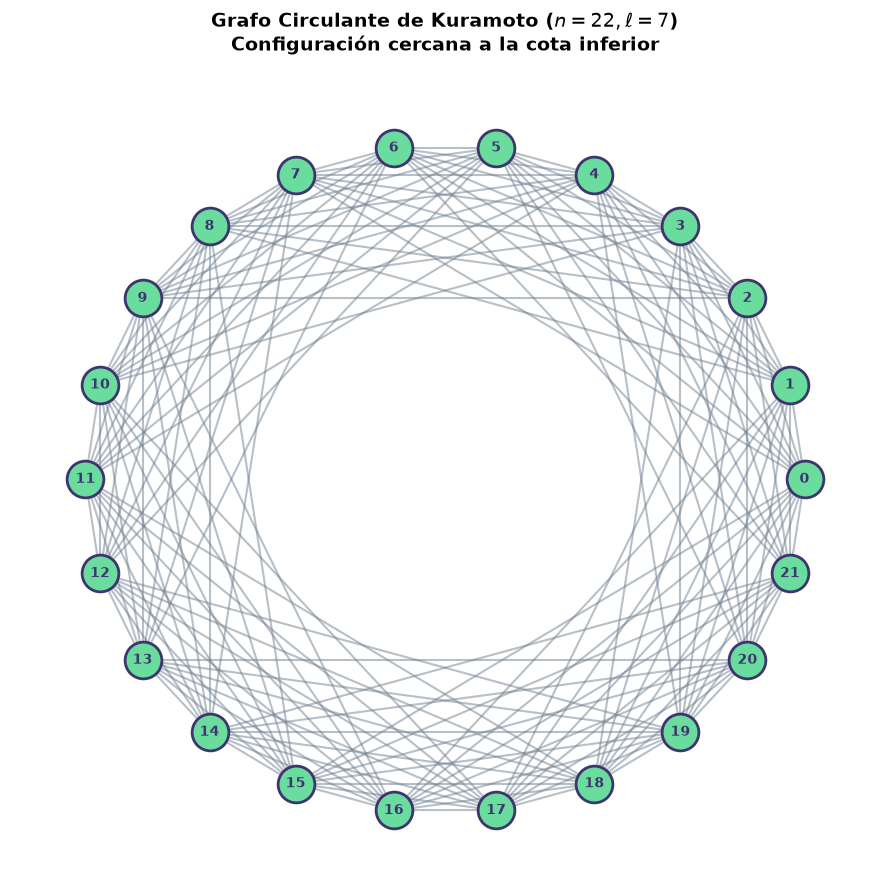

In [5]:
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np

# 1. Definición del grafo basado en los parámetros conocidos (n = 22, l = 7)[cite: 1]
n, l = 22, 7
A = np.zeros((n, n), dtype=int)
for j in range(n):
  for s in range(1, l + 1):
    A[j, (j + s) % n] = 1
    A[j, (j - s) % n] = 1

# 2. Crear el objeto grafo de NetworkX a partir de la matriz de adyacencia
G = nx.from_numpy_array(A)

# 3. Configurar el tamaño de la ventana gráfica
plt.figure(figsize=(9, 9), facecolor="white")

# Usar un layout circular para destacar la simetría del grafo circulante
pos = nx.circular_layout(G)

# 4. Dibujar los elementos con estilo profesional ("que quede lindo")
# - Aristas (edges): con un gris sutil y transparencia (alpha) para no saturar
nx.draw_networkx_edges(
    G, pos, edge_color="#708090", width=1.5, alpha=0.5, style="solid"
)

# - Nodos: con un color atractivo, bordes definidos y tamaño adecuado
nx.draw_networkx_nodes(
    G,
    pos,
    node_color="#69DC9E",  # Azul moderno
    node_size=700,
    edgecolors="#3D356E",  # Borde más oscuro para contraste
    linewidths=2.0,
)

# - Etiquetas (labels): números de nodos en blanco y negrita para legibilidad
nx.draw_networkx_labels(
    G,
    pos,
    font_size=10,
    font_color="#3D356E",
    font_weight="bold",
    font_family="sans-serif",
)

# 5. Detalles estéticos adicionales
plt.title(
    f"Grafo Circulante de Kuramoto ($n = {n}, \ell = {l}$)\n"
    r"Configuración cercana a la cota inferior",
    fontsize=14,
    fontweight="bold",
    pad=20,
)

# Ocultar los ejes cartesianos de matplotlib
plt.axis("off")
plt.tight_layout()

# 6. Mostrar el gráfico
plt.show()  